# 00. Quickstart: a virtual uMux channel in five minutes

This notebook builds a virtual microwave-SQUID-multiplexer channel from a configuration file and asks the model the
four questions the paper asks of it: how the resonance moves with flux and readout power (Sec. II), what a VNA would see
(Sec. V A, the gist of Figs. 6 and 7), what a slow flux ramp traces out in the IQ plane, and what a fast flux ramp does
once the bias line is allowed to ring (Secs. IV C and V B, the gist of Figs. 8-10). No measured data is used: the device is
the one extracted in `01_resonator_parameters` (resonator 2 of the NIST 32-channel chip, 26 Sep 2026) and the bias-line
transfer function is the one extracted in `03_flux_line_transfer_function`; both ship with the repository. Everything here
runs in a few seconds, so change any number and rerun.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import umux_cmt as uc
from umux_cmt.plotting import *      # use_style, save, SINGLE, DOUBLE, colours, grid
use_style()
DATA, CONFIGS, RESULTS = Path("../data"), Path("../configs"), Path("results")
store = uc.io.ValueStore(RESULTS / "values.json")

import time
from scipy.signal import argrelmin

CONFIG = CONFIGS / "nist_res2_2026-09-26.toml"
POLES = DATA / "flux_line_2026-10-02" / "flux_line_poles.npz"
F_PROBE = 5515.8e6          # Hz, the probe tone of the flux-ramp measurements of the paper
P_CHIP = -89                # dBm at the chip, the readout power of the paper
P_STRONG = -75              # dBm at the chip, a drive strong enough to dress the SQUID visibly
POWER_COLOR = {P_CHIP: BLUE, P_STRONG: BROWN}

## 1. The virtual device

A configuration file is the complete description of a chip: one TOML file with a `[resonators]` table ($f_0$, $Q_r$,
$|\hat Q_c|$, $\alpha$, $L_c$) and a `[squids]` table ($L_s$, $\lambda = L_s/L_J$, $M_c$, the mutuals $M_\mathrm{fr}$ and
$M_\mathrm{in}$ of the flux-ramp and detector-input lines, and the trapped flux). `configs/README.md` lists the files and
the docstring of `umux_cmt/config.py` documents the format. `uc.load_config` builds a `Multiplexer`, a list of `Channel`s
on one feedline; each channel owns an `rfSQUID` with named flux lines and reports the derived rates: $\kappa = \omega_0/Q_r$,
the linewidth $\kappa/2\pi$ and the ring-up time $2/\kappa$ (Eq. 6).

In [2]:
print(f"umux_cmt {uc.__version__}")
device = uc.load_config(CONFIG)
print(device.summary())

ch = device[0]                       # the same object as device.channels[0]
squid = ch.squid
print()
print(ch)
print(squid)
for name in ("FluxRamp", "Input", "TrappedFlux"):
    line = ch.line(name)
    print(f"  {name:<12} M = {line.M * 1e12:6.2f} pH   flux on the line = {float(line.n_phi0):+.3f} Phi0")

print()
print(f"{'bare f0':<26}{ch.f0 / 1e6:12.3f} MHz   (SQUID not loading the resonator)")
print(f"{'fr at zero ramp flux':<26}{ch.get_fr() / 1e6:12.3f} MHz   (with the trapped flux)")
print(f"{'Qc = |Qc_hat|/cos(alpha)':<26}{ch.Qc:12.0f}       (|Qc_hat| = {ch.Qc * np.cos(ch.alpha):.0f} in the file)")
print(f"{'kappa':<26}{ch.kappa / 1e6:12.2f} Mrad/s")
print(f"{'linewidth kappa/2pi':<26}{ch.linewidth / 1e3:12.0f} kHz")
print(f"{'ring-up time 2/kappa':<26}{ch.ring_up_time * 1e9:12.0f} ns")

umux_cmt 0.1.0
nist_res2_2026-09-26: 1 channel(s), Z0 = 50 Ohm
 ch   f0 (MHz)      Qr      Qc        Qi   alpha   lamb  Mc (pH)  BW (kHz)
  0   5515.689    9515   10475    103803  -0.086  0.318     3.69       580

Channel('Ch1', f0=5515.689 MHz, Qr=9515, Qc=10475, Qi=103803, alpha=-0.086)
rfSQUID(Ls=24.20 pH, lamb=0.3183, lines=[FluxRamp, TrappedFlux, Input])
  FluxRamp     M =  14.41 pH   flux on the line = +0.000 Phi0
  Input        M = 246.00 pH   flux on the line = +0.000 Phi0
  TrappedFlux  M =  14.41 pH   flux on the line = -0.444 Phi0

bare f0                       5515.689 MHz   (SQUID not loading the resonator)
fr at zero ramp flux          5515.955 MHz   (with the trapped flux)
Qc = |Qc_hat|/cos(alpha)         10475       (|Qc_hat| = 10436 in the file)
kappa                             3.64 Mrad/s
linewidth kappa/2pi                580 kHz
ring-up time 2/kappa               549 ns


The numbers come from a VNA flux sweep at $-89$ dBm at the chip, fitted in two stages in `01_resonator_parameters`.
Circle fits at every flux point give $Q_r$, $|\hat Q_c|$ and $\alpha$ (their medians over flux) and the resonance $f_r$
at each flux; a fit of $f_r$ against the ramp-line current then gives the bare $f_0$, $\lambda$, $M_c$, $M_\mathrm{fr}$
and the trapped flux. $L_s = 24.2$ pH is fixed, because it enters $f_r$ only through $M_c^2/L_s$; $L_c$ and
$M_\mathrm{in}$ are fixed design values ($L_c$ drops out of $f_r$ because the lumped model is calibrated to $f_0$). Since
the sweep was taken at finite power, $\lambda$ and $M_c$ already contain the RF dressing at $-89$ dBm, and the simulation
dresses them once more (a 3 kHz shift at that power, Step 2). The loader turns the file's $|\hat Q_c|$ into
$Q_c = |\hat Q_c|/\cos\alpha$, the coupling $Q$ that sets the rate at which energy leaks into the feedline; that is the
$Q_c$ in the summary.

## 2. Resonance versus flux and readout power

The SQUID screens the terminating inductor, $L_\mathrm{eff} = L_c - (M_c^2/L_s)\,S$, so the resonance
$f_r = 1/2\pi\sqrt{C_\mathrm{eff}(L_\mathrm{res} + L_\mathrm{eff})}$ (Eq. 7) follows the flux with period $\Phi_0$. The
screening response $S$ also depends on the RF flux that the probe tone itself puts into the SQUID, set by the energy
$E_r$ stored in the resonator (Eqs. 9 and 10, the Wegner series). We evaluate it at the on-resonance steady-state
energy, $E_r = 2Q_r^2P/(Q_c\,\omega_0)$ ($\dot a = 0$ and $\Delta = 0$ in the equation of motion), the most a probe of
power $P$ can store. The flux lines accept arrays and $S$ broadcasts, so a whole flux sweep is one call to
`ch.get_fr(Er)`. At $E_r = 0$ the SQUID does not load the resonator where $S = 0$, and there $f_r = f_0$ exactly; the
configuration references $f_0$ and the trapped flux to that point, which the ramp line reaches when it cancels the
trapped flux (marked below).

In [3]:
phi = np.linspace(-0.5, 1.5, 2001)
energies = {"Er = 0": 0.0}
for P in (P_CHIP, P_STRONG):
    energies[f"{P} dBm"] = 2 * ch.Qr ** 2 * uc.dbm_to_watt(P) / (ch.Qc * ch.omega_0)

ramp = ch.line("FluxRamp")
ramp.n_phi0 = phi
fr = {label: ch.get_fr(Er) for label, Er in energies.items()}
ramp.n_phi0 = 0.0

phi_unloaded = float(-ch.line("TrappedFlux").n_phi0) % 1       # ramp flux that cancels the trapped flux
ramp.n_phi0 = phi_unloaded
fr_unloaded, phi_tot = ch.get_fr(), squid.get_phi_tot()
ramp.n_phi0 = 0.0

fr_zero = {label: np.interp(0.0, phi, f) for label, f in fr.items()}     # at zero ramp flux
print(f"{'drive':<10}{'Er (J)':>10}{'Phi_rf (Phi0)':>15}{'fr swing p-p (kHz)':>20}{'fr(0) - f0 (kHz)':>18}"
      f"{'dressing shift (kHz)':>22}")
for label, Er in energies.items():
    print(f"{label:<10}{Er:10.2e}{ch.get_Phi_rf(Er) / uc.Phi0:15.3f}{np.ptp(fr[label]) / 1e3:20.0f}"
          f"{(fr_zero[label] - ch.f0) / 1e3:18.1f}{(fr_zero[label] - fr_zero['Er = 0']) / 1e3:22.1f}")
print(f"\nramp flux {phi_unloaded:.3f} Phi0 cancels the trapped flux: fr - f0 = {fr_unloaded - ch.f0:+.2e} Hz, "
      f"SQUID phase phi_tot = {phi_tot / np.pi:.4f} pi")

drive         Er (J)  Phi_rf (Phi0)  fr swing p-p (kHz)  fr(0) - f0 (kHz)  dressing shift (kHz)
Er = 0      0.00e+00          0.000                 972             266.2                   0.0
-89 dBm     6.28e-19          0.059                 938             262.9                  -3.3
-75 dBm     1.58e-17          0.298                 525             170.1                 -96.1

ramp flux 0.444 Phi0 cancels the trapped flux: fr - f0 = +0.00e+00 Hz, SQUID phase phi_tot = 0.5000 pi


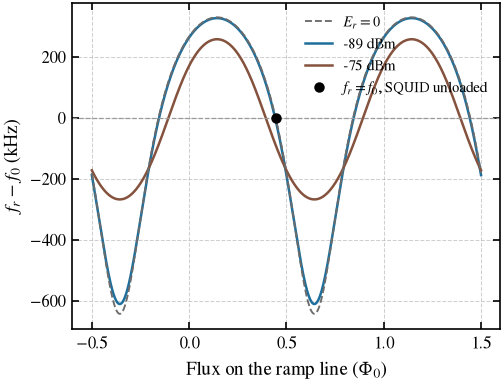

In [4]:
fig, ax = plt.subplots(figsize=(SINGLE, 2.6))
ax.plot(phi, (fr["Er = 0"] - ch.f0) / 1e3, color=GRAY, ls="--", lw=0.9, zorder=3, label="$E_r = 0$")
for P in (P_CHIP, P_STRONG):
    ax.plot(phi, (fr[f"{P} dBm"] - ch.f0) / 1e3, color=POWER_COLOR[P], label=f"{P} dBm")
ax.axhline(0, color=ZERO, ls="--", lw=0.6)
ax.plot(phi_unloaded, 0, "o", color="black", ms=4, zorder=4, label="$f_r = f_0$, SQUID unloaded")
ax.set_xlabel(r"Flux on the ramp line ($\Phi_0$)")
ax.set_ylabel(r"$f_r - f_0$ (kHz)")
ax.legend(loc="upper right", fontsize=7)
grid(ax)
save(fig, "00_resonance_vs_flux", RESULTS / "figures")
plt.show()

## 3. A virtual VNA

`uc.steady_state_sweep` is the paper's virtual VNA (Sec. V A): at every probe frequency it integrates the equation of
motion, $\dot a = -\left(i\Delta(t,|a|^2) + \kappa/2\right)a + \sqrt{\kappa_c/2}\,a_\mathrm{in}$, until the field is
steady ($20/\kappa$ from an empty cavity for the first point, $8/\kappa$ from the previous point's field after that) and
returns $S_{21} = 1 - (e^{i\alpha}/\cos\alpha)\sqrt{\kappa_c/2}\,a/a_\mathrm{in}$. The detuning
$\Delta = \omega_p - \omega_r(|a|^2)$ is evaluated at the instantaneous stored energy, so the RF dressing is
self-consistent point by point. Powers are at the chip: $-89$ dBm is the readout power of the paper and $-75$ dBm the
strong drive of Step 2. The dip is located between the 10 kHz grid points with a parabola through its three lowest points.

In [5]:
f_center = ch.get_fr()                                   # fr at zero ramp flux, Er = 0
f_sweep = f_center + np.linspace(-3e6, 3e6, 601)

sweep, t_point = {}, {}
for P in (P_CHIP, P_STRONG):
    t0 = time.perf_counter()
    sweep[P] = uc.steady_state_sweep(device, f_sweep, P)
    t_point[P] = (time.perf_counter() - t0) / len(f_sweep)


def dip(s21):
    # vertex of the parabola through the three lowest points of |S21|^2
    k = np.argmin(np.abs(s21))
    y0, y1, y2 = np.abs(s21[k - 1:k + 2]) ** 2
    return f_sweep[k] + (f_sweep[1] - f_sweep[0]) * (y0 - y2) / (2 * (y0 - 2 * y1 + y2))


f_dip = {P: dip(s21) for P, s21 in sweep.items()}
print(f"{'P_chip (dBm)':>13}{'time/point (ms)':>17}{'dip (MHz)':>12}{'dip - fr (kHz)':>16}")
for P in sweep:
    print(f"{P:13d}{t_point[P] * 1e3:17.2f}{f_dip[P] / 1e6:12.3f}{(f_dip[P] - f_center) / 1e3:16.0f}")

f_fine = f_center + np.linspace(-100e3, 100e3, 2001)
notch = uc.fitting.notch_model(f_fine, f_center, ch.Qr, ch.Qc * np.cos(ch.alpha), ch.alpha)
print(f"\nlinear notch with alpha = {ch.alpha:.3f} (uc.fitting.notch_model): |S21| minimum "
      f"{(f_center - f_fine[np.argmin(np.abs(notch))]) / 1e3:.0f} kHz below fr")
dressing = fr_zero[f"{P_STRONG} dBm"] - fr_zero[f"{P_CHIP} dBm"]
print(f"from {P_CHIP} to {P_STRONG} dBm the dip moves by {(f_dip[P_STRONG] - f_dip[P_CHIP]) / 1e3:+.0f} kHz, "
      f"the dressing shift of Step 2 by {dressing / 1e3:+.0f} kHz")

 P_chip (dBm)  time/point (ms)   dip (MHz)  dip - fr (kHz)
          -89             0.63    5515.929             -26
          -75             0.76    5515.837            -118

linear notch with alpha = -0.086 (uc.fitting.notch_model): |S21| minimum 23 kHz below fr
from -89 to -75 dBm the dip moves by -93 kHz, the dressing shift of Step 2 by -93 kHz


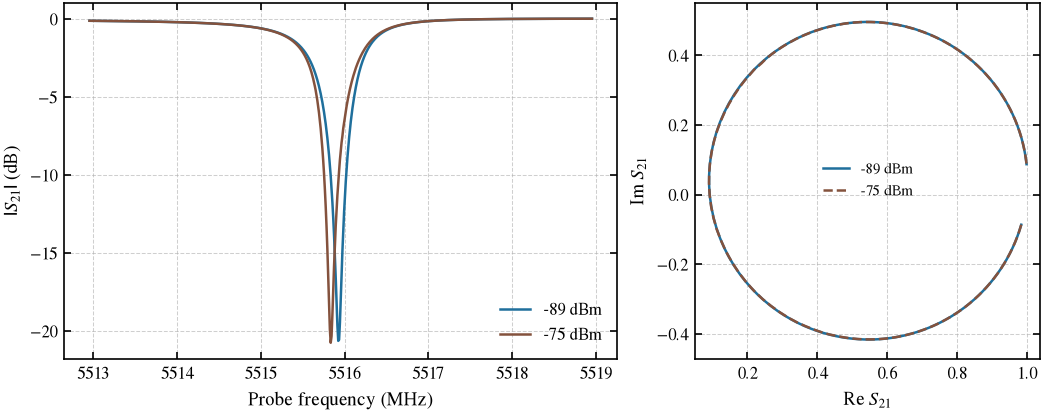

In [6]:
fig, (ax_db, ax_iq) = plt.subplots(1, 2, figsize=(DOUBLE, 2.8), gridspec_kw={"width_ratios": [1.6, 1]})
for (P, s21), ls in zip(sweep.items(), ("-", "--")):
    ax_db.plot(f_sweep / 1e6, 20 * np.log10(np.abs(s21)), color=POWER_COLOR[P], label=f"{P} dBm")
    ax_iq.plot(s21.real, s21.imag, color=POWER_COLOR[P], ls=ls, label=f"{P} dBm")
ax_db.set_xlabel("Probe frequency (MHz)")
ax_db.set_ylabel(r"$|S_{21}|$ (dB)")
ax_db.legend(loc="lower right")
ax_iq.set_xlabel(r"Re $S_{21}$")
ax_iq.set_ylabel(r"Im $S_{21}$")
ax_iq.set_aspect("equal", "datalim")
ax_iq.legend(loc="center", fontsize=7)
for ax in (ax_db, ax_iq):
    grid(ax)
save(fig, "00_virtual_vna", RESULTS / "figures")
plt.show()

Both powers trace the same circle (the $-75$ dBm one is dashed on top): the dressing only changes where each probe
frequency lands on it. Two things set where the dip falls. The coupling is asymmetric ($\alpha = -0.086$), so even the
linear notch of the circle fit has its $|S_{21}|$ minimum about 23 kHz below $f_r$; on top of that, the dressing of
Step 2 pulls the resonance down by 3 kHz at $-89$ dBm and by 96 kHz at $-75$ dBm. Between the two powers the asymmetry
offset cancels, and the dip moves with the dressing shift.

## 4. Quasi-static flux response

Now hold the probe tone at $f_p = 5515.8$ MHz and move the flux instead: twice per flux quantum the resonance sweeps
across the tone, and $S_{21}$ traces a closed, periodic curve. `uc.static_response` tabulates it from the fixed point of
the equation of motion, $a = \sqrt{\kappa_c/2}\,a_\mathrm{in}/\left(i\Delta(\Phi, E_r) + \kappa/2\right)$ with
$E_r = |a|^2$ iterated to self-consistency. That is the exact response as long as the flux at the SQUID follows the
drive and the resonance moves by much less than a linewidth per ring-up time, $|d\Delta/dt| \ll (\kappa/2)^2$. It is
what a slow flux ramp traces out, the modulation that flux-ramp readout demodulates, and the "quasi-static control" the
paper compares its dynamic simulations against. The resonator cannot tell whether the tone or the resonance moved, so
the trajectory lies on the circle of Step 3.

In [7]:
phi_grid = np.linspace(0, 1, 1001)
t0 = time.perf_counter()
static = uc.static_response(device, F_PROBE, P_CHIP, phi_grid=phi_grid)
print(f"quasi-static response on {len(phi_grid)} flux points in {time.perf_counter() - t0:.2f} s")

minima = argrelmin(np.abs(static.s21))[0]
print(f"probe {F_PROBE / 1e6:.1f} MHz is {(f_center - F_PROBE) / 1e3:.0f} kHz below fr at zero ramp flux")
print(f"|S21| dips to {np.abs(static.s21[minima]).min():.3f} at "
      + " and ".join(f"{phi_grid[k]:.3f}" for k in minima) + " Phi0, once for each crossing of the resonance")
print(f"I in [{static.s21.real.min():.3f}, {static.s21.real.max():.3f}],  "
      f"Q in [{static.s21.imag.min():.3f}, {static.s21.imag.max():.3f}]")

quasi-static response on 1001 flux points in 0.28 s
probe 5515.8 MHz is 155 kHz below fr at zero ramp flux
|S21| dips to 0.091 at 0.382 and 0.905 Phi0, once for each crossing of the resonance
I in [0.090, 0.909],  Q in [-0.385, 0.495]


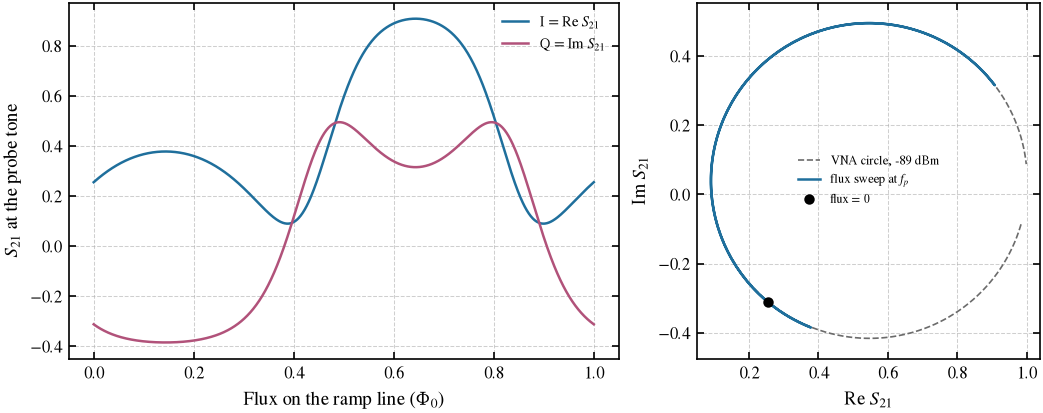

In [8]:
fig, (ax_t, ax_iq) = plt.subplots(1, 2, figsize=(DOUBLE, 2.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax_t.plot(phi_grid, static.s21.real, color=BLUE, label="I = Re $S_{21}$")
ax_t.plot(phi_grid, static.s21.imag, color=ROSE, label="Q = Im $S_{21}$")
ax_t.set_xlabel(r"Flux on the ramp line ($\Phi_0$)")
ax_t.set_ylabel("$S_{21}$ at the probe tone")
ax_t.legend(loc="upper right", fontsize=7)
ax_iq.plot(sweep[P_CHIP].real, sweep[P_CHIP].imag, color=GRAY, ls="--", lw=0.8, label=f"VNA circle, {P_CHIP} dBm")
ax_iq.plot(static.s21.real, static.s21.imag, color=BLUE, label="flux sweep at $f_p$")
ax_iq.plot(static.s21.real[0], static.s21.imag[0], "o", color="black", ms=4, zorder=3, label="flux = 0")
ax_iq.set_xlabel(r"Re $S_{21}$")
ax_iq.set_ylabel(r"Im $S_{21}$")
ax_iq.set_aspect("equal", "datalim")
ax_iq.legend(loc="center", fontsize=6)
for ax in (ax_t, ax_iq):
    grid(ax)
save(fig, "00_quasi_static_response", RESULTS / "figures")
plt.show()

## 5. Time domain: a fast flux ramp through the bias line

A 100 kHz sawtooth of $0.946\,\Phi_0$ per period lasts only 18 ring-up times, and its reset is an edge the bias line
cannot follow. The line is an all-pole filter from source current to coil current,
$H(f) = \prod_k (1 - if/p_k)^{-1}$ with $H(0) = 1$ (Eq. 30, poles from `03_flux_line_transfer_function`), and its
dominant pole pair at 4.53 MHz with $Q \approx 5.6$ makes the coil current ring for about two microseconds (five 395 ns
decay times) after each reset. We drive the model with the ideal sawtooth and with the sawtooth through $H(f)$
(`apply_periodic` filters each harmonic: the steady state of a line driven for ever), converted to coil current with
$I = \Phi/M_\mathrm{fr}$. `uc.simulate` starts from the quasi-static state 5 $\mu$s before the reset and integrates one
period in steps of at most 20 ns. The ramp amplitude was measured at the source in `03` and the reset flux fitted to the
1 kHz record in `06` (paper values until those notebooks run).

In [9]:
RATE = 100e3
T = 1 / RATE
ramp_amp = store.value("RampAmpPhi", default=0.946)      # Phi0 swept per period, measured at the source (03)
phi_reset = store.value("IQPhiReset", default=0.184)     # ramp-line flux at the reset, fitted at 1 kHz (06)

tf = uc.FluxLineTF.from_file(POLES)
print(tf)
print(f"{'mode (MHz)':>11}{'Q':>7}{'1/e decay (ns)':>16}")
for f_mode, Q, tau in tf.mode_table():
    print(f"{f_mode / 1e6:11.2f}{Q:7.1f}{tau * 1e9:16.0f}")

ideal = uc.signals.sawtooth(RATE, amplitude=ramp_amp, offset=phi_reset)
through_line = tf.apply_periodic(ideal, T)
rate_param = 2 * np.pi * np.abs(np.gradient(fr[f"{P_CHIP} dBm"], phi)) * ramp_amp * RATE / (ch.kappa / 2) ** 2
print(f"\nramp: {ramp_amp:.3f} Phi0 per period at {RATE / 1e3:g} kHz from a reset flux of {phi_reset:.3f} Phi0, "
      f"{ramp_amp * uc.Phi0 / ramp.M * 1e6:.1f} uA peak-to-peak in the coil")
print(f"sweep-rate parameter |dDelta/dt|/(kappa/2)^2 of the ideal ramp: up to {rate_param.max():.2f}, "
      f"median {np.median(rate_param):.2f}")

t_out = np.arange(2000) / 2000 / RATE                    # one period, reset at t = 0
drives = {"ideal sawtooth": ideal, "through H(f)": through_line}
result = {}
print()
for name, flux in drives.items():
    I_coil = uc.signals.flux_to_current(flux, ramp.M, uc.Phi0)
    t0 = time.perf_counter()
    result[name] = uc.simulate(device, F_PROBE, P_CHIP, t_out=t_out, flux_ramp_current_func=I_coil,
                               max_step=min(20e-9, T / 500))
    print(f"{name:<16} one period simulated in {time.perf_counter() - t0:.2f} s")

rms = lambda x: np.sqrt(np.mean(np.abs(x) ** 2))
early = t_out < 2e-6
distances = {"ideal drive to quasi-static curve": result["ideal sawtooth"].s21 - static(ideal(t_out) % 1),
             "through H(f) to ideal drive": result["through H(f)"].s21 - result["ideal sawtooth"].s21}
print(f"\n{'rms distance in S21':<36}{'first 2 us':>12}{'rest of period':>16}")
for name, d in distances.items():
    print(f"{name:<36}{rms(d[early]):12.3f}{rms(d[~early]):16.3f}")

FluxLineTF(8 poles: 4.53 MHz (Q 5.6), 14.02 MHz (Q 6.2), 22.88 MHz (Q 11.3), 33.89 MHz (Q 7.4))
 mode (MHz)      Q  1/e decay (ns)
       4.53    5.6             395
      14.02    6.2             142
      22.88   11.3             157
      33.89    7.4              70

ramp: 0.946 Phi0 per period at 100 kHz from a reset flux of 0.184 Phi0, 135.8 uA peak-to-peak in the coil
sweep-rate parameter |dDelta/dt|/(kappa/2)^2 of the ideal ramp: up to 0.71, median 0.30

ideal sawtooth   one period simulated in 0.09 s


through H(f)     one period simulated in 0.15 s

rms distance in S21                   first 2 us  rest of period
ideal drive to quasi-static curve          0.085           0.188
through H(f) to ideal drive                0.327           0.011


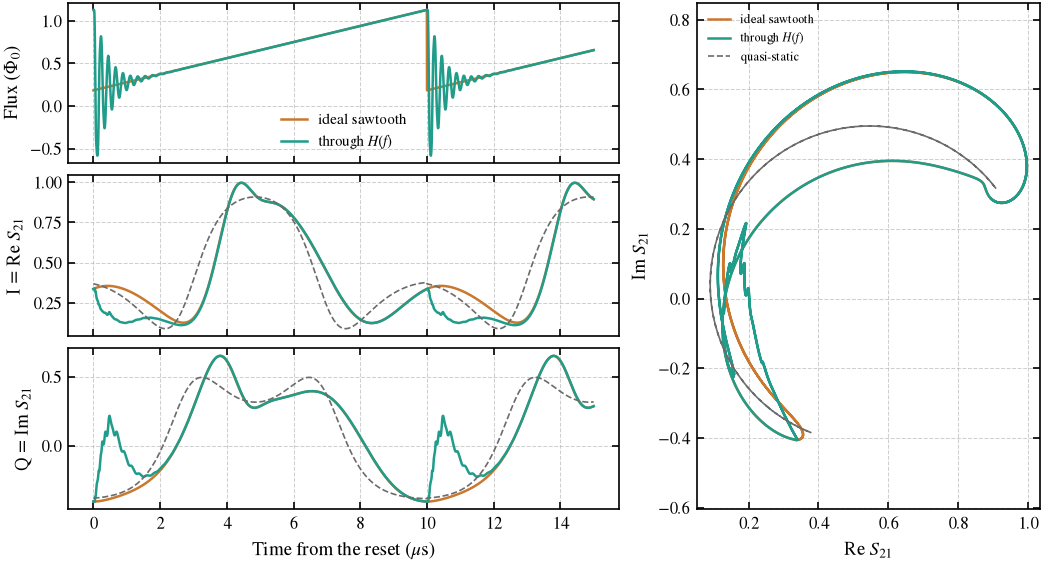

In [10]:
looks = {"ideal sawtooth": (MODEL_IDEAL, "ideal sawtooth"), "through H(f)": (MODEL_TF, "through $H(f)$")}
t_plot = np.linspace(0, 1.5 * T, 3000)
fig = plt.figure(figsize=(DOUBLE, 3.8))
gs = fig.add_gridspec(3, 2, width_ratios=[1.6, 1])
ax_flux = fig.add_subplot(gs[0, 0])
ax_i = fig.add_subplot(gs[1, 0], sharex=ax_flux)
ax_q = fig.add_subplot(gs[2, 0], sharex=ax_flux)
ax_iq = fig.add_subplot(gs[:, 1])
for name, flux in drives.items():
    color, label = looks[name]
    z = uc.periodic_interpolant(t_out, result[name].s21, T)(t_plot)
    ax_flux.plot(t_plot * 1e6, flux(t_plot), color=color, label=label)
    ax_i.plot(t_plot * 1e6, z.real, color=color)
    ax_q.plot(t_plot * 1e6, z.imag, color=color)
    ax_iq.plot(z.real, z.imag, color=color, label=label)
z_static = static(ideal(t_plot) % 1)
ax_i.plot(t_plot * 1e6, z_static.real, color=GRAY, ls="--", lw=0.8)
ax_q.plot(t_plot * 1e6, z_static.imag, color=GRAY, ls="--", lw=0.8)
ax_iq.plot(static.s21.real, static.s21.imag, color=GRAY, ls="--", lw=0.8, label="quasi-static")
ax_flux.set_ylabel(r"Flux ($\Phi_0$)")
ax_i.set_ylabel("I = Re $S_{21}$")
ax_q.set_ylabel("Q = Im $S_{21}$")
ax_q.set_xlabel(r"Time from the reset ($\mu$s)")
ax_flux.legend(loc="lower center", fontsize=7)
ax_iq.set_xlabel(r"Re $S_{21}$")
ax_iq.set_ylabel(r"Im $S_{21}$")
ax_iq.set_aspect("equal", "datalim")
ax_iq.legend(loc="upper left", fontsize=6)
for ax in (ax_flux, ax_i):
    ax.tick_params(labelbottom=False)
for ax in (ax_flux, ax_i, ax_q, ax_iq):
    grid(ax)
save(fig, "00_flux_ramp_time_domain", RESULTS / "figures")
plt.show()

Two things happen here that the quasi-static picture (gray, dashed) misses. Even with the ideal sawtooth the loop in the
IQ plane opens up beyond the quasi-static one: where the response is steep the resonance crosses the probe tone in a few
ring-up times, the sweep-rate parameter printed above reaches 0.7, and the field lags the flux. That lag sits on the
steep parts of the ramp more than at the reset (first row of the rms table), and it is the resonator dynamics the paper
measures at ramp rates up to 2 MHz (Sec. V B). Through $H(f)$ the coil flux also overshoots and rings at 4.53 MHz after
every reset, and $I$ and $Q$ ring with it for about two microseconds (second row); in the measured records this ringing,
not the ring-up, is the dominant transient. Away from the reset the two drives agree to about a per cent.

## What to try next

* **Change the ramp rate.** Set `RATE = 10e3` and the ideal-drive trace collapses onto the quasi-static curve, while the
  trace through $H(f)$ still rings for about 2 $\mu$s after every reset. Set `RATE = 1e6` and the period is less than
  two ring-up times and only 2.5 decay times of the bias line, so neither the resonator nor the coil ever settles
  (compare with Fig. 10 of the paper, or with `06_flux_ramp_response`).
* **Use the other configuration.** `nist_res2_2026-10-04.toml` is the same resonator one week later, with its bare
  frequency 383 kHz lower; load it, probe at 5515.030 MHz as the pulse measurements did, and rerun Steps 3-5.
* **Drive the detector input instead.** Replace the ramp with a detector-like pulse on the `Input` line, whose mutual
  is 17 times larger than the ramp line's: `pulse = uc.signals.exponential_pulse(0.02, 2e-6, 50e-6, 200e-6)` and
  `uc.simulate(..., input_current_func=uc.signals.flux_to_current(pulse, ch.line("Input").M, uc.Phi0))`, with a ramp
  on the `FluxRamp` line at the same time if you want to see both. To simulate your own device, write a configuration
  for it (`configs/README.md`): the model needs a circle fit and a flux-response fit of a VNA flux sweep, the fixed
  $L_s$, $L_c$ and $M_\mathrm{in}$, and, for fast drives, the transfer function of your bias line (`03`).

**The rest of the series** (they pass numbers to one another through `results/values.json`):

| Notebook | What it does |
|---|---|
| `01_resonator_parameters` | cable delay, circle fits, the flux-response fit; writes the configuration files (Table I, Fig. 3) |
| `02_all_channels` | all 32 channels of the chip from one sweep; a multi-channel simulation (Fig. 4) |
| `03_flux_line_transfer_function` | the poles of the bias line from its two-port; the ramp amplitude (Fig. 5, Table II) |
| `04_steady_state_s21` | the virtual VNA against the measured resonance (Fig. 6) |
| `05_power_dependence` | the RF dressing against a VNA power sweep; the one fitted attenuation (Fig. 7) |
| `06_flux_ramp_response` | flux-ramp IQ records at 28 rates, calibrated once at 1 kHz and predicted at the others (Figs. 8-10, Table III) |
| `07_square_pulse_response` | square flux pulses through the bias line (Fig. 11, Table III) |
| `08_demodulation_extension` | beyond the paper: a detector pulse through flux-ramp demodulation |